In [2]:
import numpy as np
import matplotlib.pyplot as plt
import scipy
from numpy.linalg import eigh

In [3]:
#Use natural units so that hbar =1
def hamiltonian(Omega, Delta, phi, V):

    H = 0.5*np.array([[2*Delta, Omega*np.exp(-1j*phi),Omega*np.exp(-1j*phi), 0],
                  [Omega*np.exp(1j*phi), 0, 0, Omega*np.exp(-1j*phi)], 
                  [Omega*np.exp(1j*phi), 0, 0, Omega*np.exp(-1j*phi)], 
                  [0, Omega*np.exp(1j*phi), Omega*np.exp(1j*phi), -2*Delta + 2*V]])
    return H

In [4]:
psi0 = np.array([1, 0, 0, 0])  # Initial

In [5]:
#generate a time array
t_max = 1e-6 # Max time in seconds
times = np.linspace(0, t_max, 1000)

In [6]:
Omega = 2*np.pi*10**6 # Rabi frequency in Hz
Delta = 0
phi = 0
V = 0

H = hamiltonian(Omega, Delta, phi, V)

In [7]:
#Find eigenvalues and eigenvectors of the Hamiltonian
def solve_static(H, psi0, times):
    eigenvalues, eigenvectors = eigh(H)
    coeffs = eigenvectors.conj().T @ psi0
    states = []
    for t in times:
        phase = np.exp(-1j * eigenvalues * t)
        psi_t = eigenvectors @ (coeffs * phase)
        states.append(psi_t)
    return np.array(states)
    

In [8]:
#Check
#eigenvalues, eigenvectors = eigh(H)
#coeffs = eigenvectors.conj().T @ psi0
#print(np.sum(np.abs(coeffs)**2))
#print(eigenvectors.conj().T @ eigenvectors)
#print(psi0)

In [9]:
states = solve_static(H, psi0, times)

In [10]:
#Find probabilities of each state
probabilities = np.abs(states)**2
print(probabilities)

[[1.00000000e+00 1.92592994e-32 6.93334780e-33 7.70371978e-32]
 [9.99980221e-01 9.88924286e-06 9.88924286e-06 9.77990587e-11]
 [9.99920888e-01 3.95554067e-05 3.95554067e-05 1.56475399e-09]
 ...
 [9.99920888e-01 3.95554067e-05 3.95554067e-05 1.56475399e-09]
 [9.99980221e-01 9.88924286e-06 9.88924286e-06 9.77990587e-11]
 [1.00000000e+00 3.42568973e-32 2.19309456e-32 1.64022129e-31]]


In [11]:
P00 = probabilities[:,0]

In [12]:
#Check
Total = probabilities[1,0] + probabilities[1,1] + probabilities[1,2] + probabilities[1,3]
print(Total)

1.0000000000000004


<>:6: SyntaxWarning: invalid escape sequence '\m'
<>:6: SyntaxWarning: invalid escape sequence '\m'
C:\Users\oscar\AppData\Local\Temp\ipykernel_10052\3237991347.py:6: SyntaxWarning: invalid escape sequence '\m'
  plt.xlabel('Time($\mu$s)')


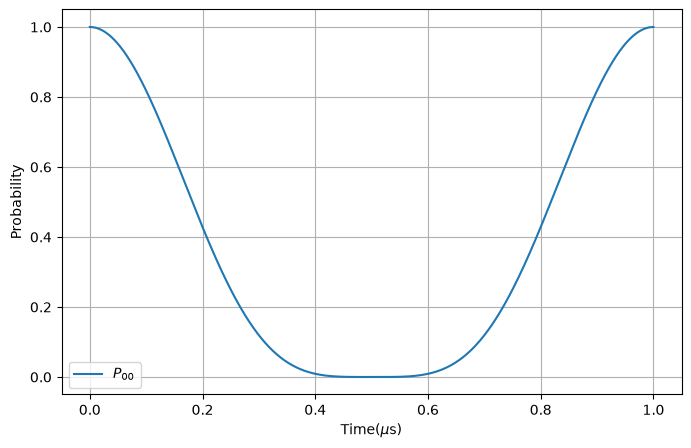

In [13]:
# Plot of probability for 00 state over time with V=0

plt.figure(figsize=(8,5))

plt.plot(times * 1e6, P00, label=r'$P_{00}$')
plt.xlabel('Time($\mu$s)')
plt.ylabel('Probability')
#plt.title('Probability of $|00\rangle$ for V = 0')
plt.grid(True)
plt.legend()
plt.show()

<>:14: SyntaxWarning: invalid escape sequence '\m'
<>:14: SyntaxWarning: invalid escape sequence '\m'
C:\Users\oscar\AppData\Local\Temp\ipykernel_10052\379285454.py:14: SyntaxWarning: invalid escape sequence '\m'
  plt.xlabel('Time($\mu$s)')
C:\Users\oscar\AppData\Local\Temp\ipykernel_10052\379285454.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


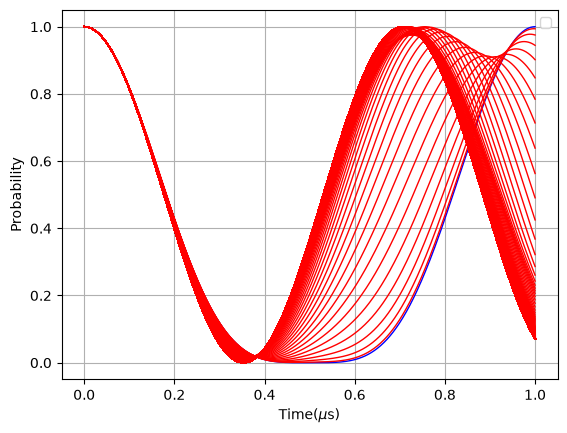

In [21]:
# Plot the probability of 00 state for a range of V values
V_values = np.linspace(0, 2*np.pi*100*10**6, 1000) # V values from 0 to 200pi MHz

# for loop to plot over this range of V_values
for V in V_values:
    H = hamiltonian(Omega, Delta, phi, V)
    states = solve_static(H, psi0, times)
    probabilities = np.abs(states)**2
    P00 = probabilities[:,0]
    colour = 'blue' if V == 0 else 'red'

    
    plt.plot(times * 1e6, P00, color = colour, linewidth = 1)
plt.xlabel('Time($\mu$s)')
plt.ylabel('Probability')
plt.grid(True)
plt.legend()
plt.show()

<>:19: SyntaxWarning: invalid escape sequence '\m'
<>:19: SyntaxWarning: invalid escape sequence '\m'
C:\Users\oscar\AppData\Local\Temp\ipykernel_10052\795781555.py:19: SyntaxWarning: invalid escape sequence '\m'
  plt.xlabel('Time($\mu$s)')


TypeError: alpha must be numeric or None, not <class 'dict'>

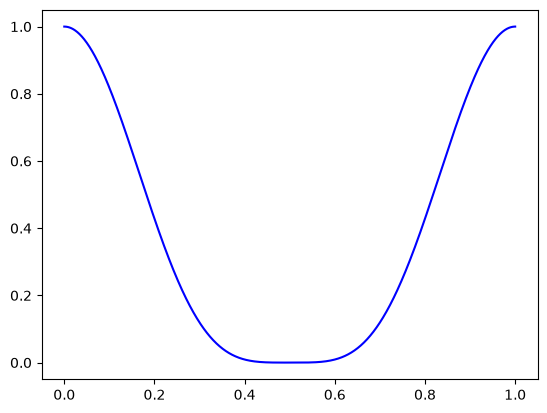

In [22]:
# Improved formatting
# Plot the probability of 00 state for a range of V values
V_values = np.linspace(0, 2*np.pi*100*10**6, 1000) # V values from 0 to 200pi MHz

# for loop to plot over this range of V_values
for V in V_values:
    H = hamiltonian(Omega, Delta, phi, V)
    states = solve_static(H, psi0, times)
    probabilities = np.abs(states)**2
    P00 = probabilities[:,0]

    if V == 0:
        plt.plot(times * 1e6, P00, color = 'blue')

    else:
        alpha = {1:1.0, 10*10**3:0.6, 10*10**6:0.3}
        plt.plot(times, P00, color = 'red', alpha = alpha)

plt.xlabel('Time($\mu$s)')
plt.ylabel('Probability')
plt.grid(True)
plt.legend()
plt.show()